# Particle analysis first projekt

First thoughts

In [ ]:
## i ask chat gpt vor a code base
## imports
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import os

# Read the CSV file
data = pd.read_csv("Data_Size/Results_173_Bild7.csv")
data = data.iloc[:-4]   # Remove last 4 Rows
lengths = data["Length"]
# Show the first 5 rows
print(lengths.head())

print(lengths.info())

0    3.423
1    2.977
2    2.232
3    3.500
4    1.415
Name: Length, dtype: float64
<class 'pandas.Series'>
RangeIndex: 246 entries, 0 to 245
Series name: Length
Non-Null Count  Dtype  
--------------  -----  
246 non-null    float64
dtypes: float64(1)
memory usage: 2.1 KB
None


count    246.000000
mean       2.452931
std        1.162692
min        0.603000
25%        1.660500
50%        2.136500
75%        2.983000
max        7.812000
Name: Length, dtype: float64


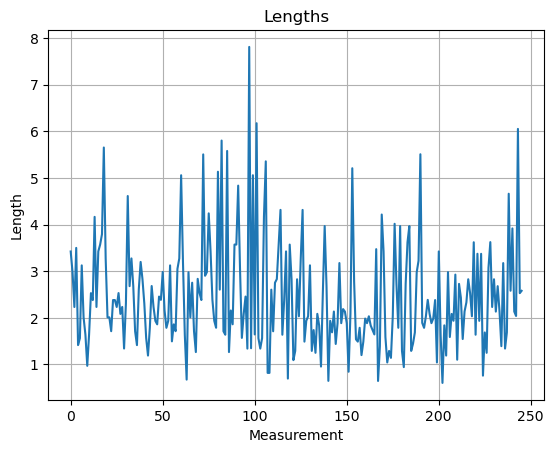

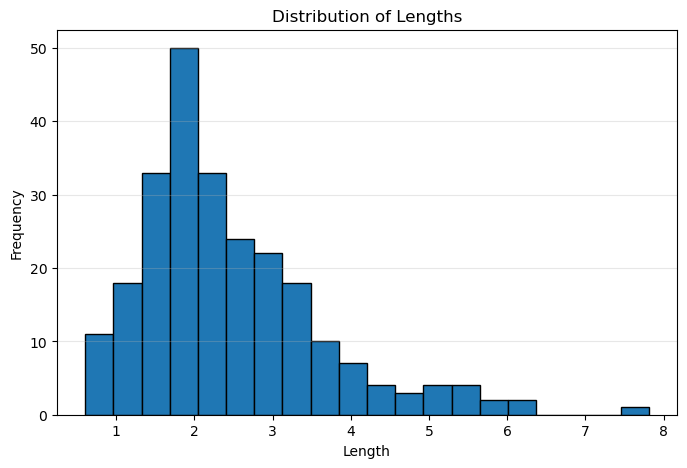

In [ ]:
# Statistics
print(lengths.describe())

# Plot every single measurment
plt.plot(lengths)
plt.xlabel("Measurement")
plt.ylabel("Length")
plt.title("Lengths")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(lengths, bins=20, edgecolor="black")
plt.title("Distribution of Lengths")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Function Data Extraction

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Read data
# -----------------------------
def analyze_file(filename):
    
    data = pd.read_csv(filename)

# Remove rows with content in Label only if the column exists
    if "Label" in data.columns:
        data = data[ data["Label"].isna() |(data["Label"].astype(str).str.strip() == "") ]
    else:
        print("No Label column found -> using all rows")
# Select column
    lengths = data["Length"]
    
    # -----------------------------
    # Create output folder
    # -----------------------------
    base_name = os.path.splitext(os.path.basename(filename))[0]
    print(base_name)
    output_folder = base_name + "_folder"

    os.makedirs(output_folder, exist_ok=True)

    # -----------------------------
    # Statistics
    # -----------------------------
    stats = pd.DataFrame({
        "Statistic": [
            "Count",
            "Mean",
            "Median",
            "Standard Deviation",
            "Variance",
            "Minimum",
            "Maximum"
        ],
        "Value": [
            lengths.count(),
            lengths.mean(),
            lengths.median(),
            lengths.std(),
            lengths.var(),
            lengths.min(),
            lengths.max()
        ]
    })

    # Save statistics as CSV
    stats.to_csv(os.path.join(output_folder, f"length_statistics_{base_name}.csv"),
                index=False)


    # -----------------------------
    # Plot measurements
    # -----------------------------
    plt.figure(figsize=(10,5))
    plt.plot(lengths)
    plt.xlabel("Measurement Number")
    plt.ylabel("Length")
    plt.title("Length Measurements")
    plt.grid(True)

    plt.savefig(os.path.join(output_folder, f"length_measurements_{base_name}.png"),
                dpi=300,
                bbox_inches="tight")

    plt.close()

    # -----------------------------
    # Histogram
    # -----------------------------
    plt.figure(figsize=(8,5))
    plt.hist(lengths, bins=20, edgecolor="black")
    plt.xlabel("Length")
    plt.ylabel("Frequency")
    plt.title("Length Distribution")
    plt.grid(axis="y", alpha=0.3)

    plt.savefig(os.path.join(output_folder, f"length_distribution_{base_name}.png"),
                dpi=300,
                bbox_inches="tight")

    plt.close()

    print(stats)
    print(f"Results saved in: {output_folder}")





## LOOP over Files

In [ ]:
import os
print(os.__file__)

c:\Miniforge3\envs\jlab\Lib\os.py


In [ ]:
from pathlib import Path
import os

folder = Path(r"C:\Users\fbeer\Downloads\VCS\Programming test\Data_Size")

output_root = Path(r"C:\Users\fbeer\Downloads\VCS\Programming test")

for files in folder.iterdir():
 # Dateiname ohne Endung
    base_name = files.stem

# Erwarteter Ausgabeordner
    output_folder = output_root / f"{base_name}_folder"

# Prüfen ob Ordner bereits existiert
    if output_folder.exists():
        print(f"Überspringe {files.name}, Ordner existiert bereits.")
        continue
    print(files)
    analyze_file(files)

Überspringe Results Linien_169.csv, Ordner existiert bereits.
Überspringe Results_143.csv, Ordner existiert bereits.
Überspringe Results_169_15_three.csv, Ordner existiert bereits.
Überspringe Results_169_Bild14_two.csv, Ordner existiert bereits.
Überspringe Results_171_Bild1.csv, Ordner existiert bereits.
Überspringe Results_173_Bild7.csv, Ordner existiert bereits.
Überspringe Results_SaarXXX.csv, Ordner existiert bereits.
